In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df1 = pd.read_excel(r"../data/online_retail_II.xlsx",sheet_name="Year 2009-2010")
df2 = pd.read_excel(r"../data/online_retail_II.xlsx",sheet_name="Year 2010-2011")


In [3]:
print("First Sheet (Year 2009-2010)")
print(df1.head())
print("Dataset Shape:", df1.shape)

print("\nSecond Sheet (Year 2010-2011)")
print(df2.head())
print("Dataset Shape:", df2.shape)

First Sheet (Year 2009-2010)
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom  
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom  
Dataset Shape: (525461, 8)

Second Sheet (Year 2010-2011)
  Invoice StockCode                          Description  Quantity  \
0  536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER      

In [4]:
df = pd.concat([df1,df2], ignore_index=True)
# Dataset dimensions
print("Combined Shape",df.shape)

# Column information
df.info()

Combined Shape (1067371, 8)
<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 78.8+ MB


In [5]:
# Statistical summary
print(df.describe())

# Missing values
df.isnull().sum()

           Quantity                 InvoiceDate         Price    Customer ID
count  1.067371e+06                     1067371  1.067371e+06  824364.000000
mean   9.938898e+00  2011-01-02 21:13:55.394029  4.649388e+00   15324.638504
min   -8.099500e+04         2009-12-01 07:45:00 -5.359436e+04   12346.000000
25%    1.000000e+00         2010-07-09 09:46:00  1.250000e+00   13975.000000
50%    3.000000e+00         2010-12-07 15:28:00  2.100000e+00   15255.000000
75%    1.000000e+01         2011-07-22 10:23:00  4.150000e+00   16797.000000
max    8.099500e+04         2011-12-09 12:50:00  3.897000e+04   18287.000000
std    1.727058e+02                         NaN  1.235531e+02    1697.464450


Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [6]:
# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Unique customers, products and countries
print("\nUnique Customers:", df['Customer ID'].nunique())
print("Unique Products:", df['StockCode'].nunique())
print("Unique Countries:", df['Country'].nunique())


Duplicate Records: 34335

Unique Customers: 5942
Unique Products: 5305
Unique Countries: 43


In [7]:
# Date range
print("\nDate Range:")
print("Start:", df['InvoiceDate'].min())
print("End:", df['InvoiceDate'].max())

# Negative quantities and prices
print("\nNegative Quantities:", (df['Quantity'] < 0).sum())
print("Negative Prices:", (df['Price'] < 0).sum())


Date Range:
Start: 2009-12-01 07:45:00
End: 2011-12-09 12:50:00

Negative Quantities: 22950
Negative Prices: 5


In [8]:
df_clean = df.copy()

df_clean = df_clean.dropna(subset=["Customer ID"])

df_clean = df_clean.drop_duplicates()

df_clean.info()

print(df_clean.isnull().sum())

df_clean["Customer ID"] = (df_clean["Customer ID"].astype(int))

cancelled = df_clean[df_clean["Invoice"].astype(str).str.startswith("C")]

print("Cancelled transactions:",len(cancelled))

<class 'pandas.DataFrame'>
Index: 797885 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      797885 non-null  object        
 1   StockCode    797885 non-null  object        
 2   Description  797885 non-null  object        
 3   Quantity     797885 non-null  int64         
 4   InvoiceDate  797885 non-null  datetime64[us]
 5   Price        797885 non-null  float64       
 6   Customer ID  797885 non-null  float64       
 7   Country      797885 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.0+ MB
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64
Cancelled transactions: 18390


In [30]:
df_clean[~df_clean["Invoice"].astype(str).str.startswith("C")]

print("Negative Quantity:",(df_clean["Quantity"]<0).sum())
print("Zero Quantity:",(df_clean["Quantity"]==0).sum())

print("Negative Price:",(df["Price"]<0).sum())
print("Zero Price:",(df["Price"]==0).sum())

df_clean = df_clean[
    (df_clean["Quantity"]>0) & (df_clean["Price"]>0)
    ]

Negative Quantity: 0
Zero Quantity: 0
Negative Price: 5
Zero Price: 6202


In [31]:
print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicates:", df_clean.duplicated().sum())

print("\nData Types:")
print(df_clean.dtypes)

df_clean.describe()

Original Shape: (1067371, 8)
Cleaned Shape: (779425, 10)

Missing Values:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
TotalPrice     0
YearMonth      0
dtype: int64

Duplicates: 0

Data Types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID             int64
Country                   str
TotalPrice            float64
YearMonth           period[M]
dtype: object


,Quantity,InvoiceDate,Price,Customer ID,TotalPrice
count,779425.000000,779425,779425.000000,779425.000000,779425.000000
mean,13.489370,2011-01-03 01:44:42.593476,3.218488,15320.360461,22.291823
min,1.000000,2009-12-01 07:45:00,0.001000,12346.000000,0.001000
25%,2.000000,2010-07-02 14:39:00,1.250000,13971.000000,4.950000
50%,6.000000,2010-12-02 14:09:00,1.950000,15247.000000,12.480000
75%,12.000000,2011-08-01 13:44:00,3.750000,16794.000000,19.800000
max,80995.000000,2011-12-09 12:50:00,10953.500000,18287.000000,168469.600000
std,145.855814,NaN,29.676140,1695.692775,227.427075


In [32]:
df_clean.to_csv("../data/cleaned_retail_data.csv",index=False)

In [33]:
# Feature Engineering
df_clean["TotalPrice"] = df_clean["Quantity"]*df_clean["Price"]

In [34]:
print("Total revenue:",df_clean["TotalPrice"].sum())
print("Number of unique customers:",df_clean["Customer ID"].nunique())
print("Total transactions:",df_clean["Invoice"].nunique())
print("Countries:",df_clean["Country"].nunique())
print("Unique products:",df_clean["StockCode"].nunique())

Total revenue: 17374804.268
Number of unique customers: 5878
Total transactions: 36969
Countries: 41
Unique products: 4631


In [35]:
df_clean["YearMonth"] = df_clean["InvoiceDate"].dt.to_period("M")

monthly_sales = df_clean.groupby("YearMonth")["TotalPrice"].sum()
monthly_sales

YearMonth
2009-12     683504.010
2010-01     555802.672
2010-02     504558.956
2010-03     696978.471
2010-04     591982.002
2010-05     597833.380
2010-06     636371.130
2010-07     589736.170
2010-08     602224.600
2010-09     829013.951
2010-10    1033112.010
2010-11    1166460.022
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517208.440
Freq: M, Name: TotalPrice, dtype: float64

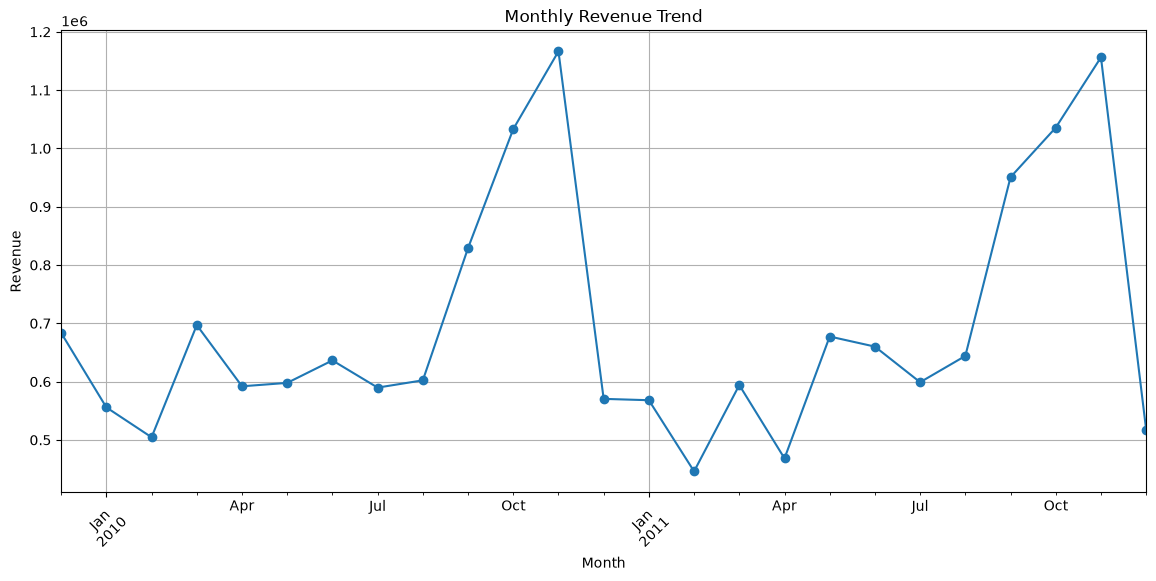

In [36]:
plt.figure(figsize=(14,6))

monthly_sales.plot(kind="line",marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [37]:
print("Highest Revenue Month:")
print(monthly_sales.idxmax(), monthly_sales.max())

print("\nLowest Revenue Month:")
print(monthly_sales.idxmin(), monthly_sales.min())

Highest Revenue Month:
2010-11 1166460.022

Lowest Revenue Month:
2011-02 446084.9199999999


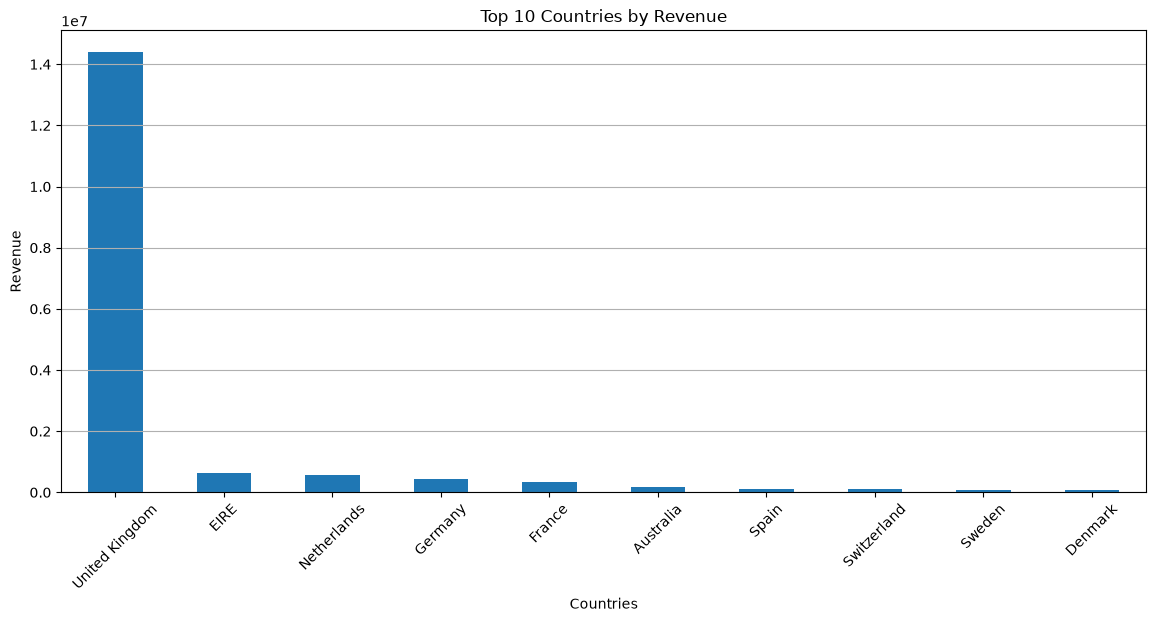

In [38]:
country_sales = df_clean.groupby("Country")["TotalPrice"].sum().sort_values(ascending=False)
country_sales.head(10)

plt.figure(figsize=(14,6))

country_sales.head(10).plot(kind="bar")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Countries")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.show()


In [39]:
country_contribution = (country_sales/country_sales.sum())*100
country_contribution

Country
United Kingdom          82.816673
EIRE                     3.548647
Netherlands              3.188744
Germany                  2.446184
France                   2.007326
Australia                0.974304
Spain                    0.623503
Switzerland              0.575903
Sweden                   0.526716
Denmark                  0.394713
Belgium                  0.376337
Norway                   0.324162
Portugal                 0.319743
Channel Islands          0.256828
Japan                    0.247622
Italy                    0.184797
Finland                  0.172235
Singapore                0.145711
Cyprus                   0.143023
Austria                  0.135904
Greece                   0.109907
Poland                   0.061320
Israel                   0.059945
United Arab Emirates     0.052966
Unspecified              0.049539
USA                      0.048155
Malta                    0.046614
Iceland                  0.028326
Lithuania                0.028160
Canada

In [40]:
top_products_quantity = (
    df_clean.groupby("Description")["Quantity"]
    .sum().
    sort_values(ascending=False).
    head(10)
)

print(top_products_quantity)

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     105185
WHITE HANGING HEART T-LIGHT HOLDER     91757
PAPER CRAFT , LITTLE BIRDIE            80995
ASSORTED COLOUR BIRD ORNAMENT          78234
MEDIUM CERAMIC TOP STORAGE JAR         77916
JUMBO BAG RED RETROSPOT                74224
BROCADE RING PURSE                     70082
PACK OF 60 PINK PAISLEY CAKE CASES     54592
60 TEATIME FAIRY CAKE CASES            52828
PACK OF 72 RETRO SPOT CAKE CASES       45129
Name: Quantity, dtype: int64


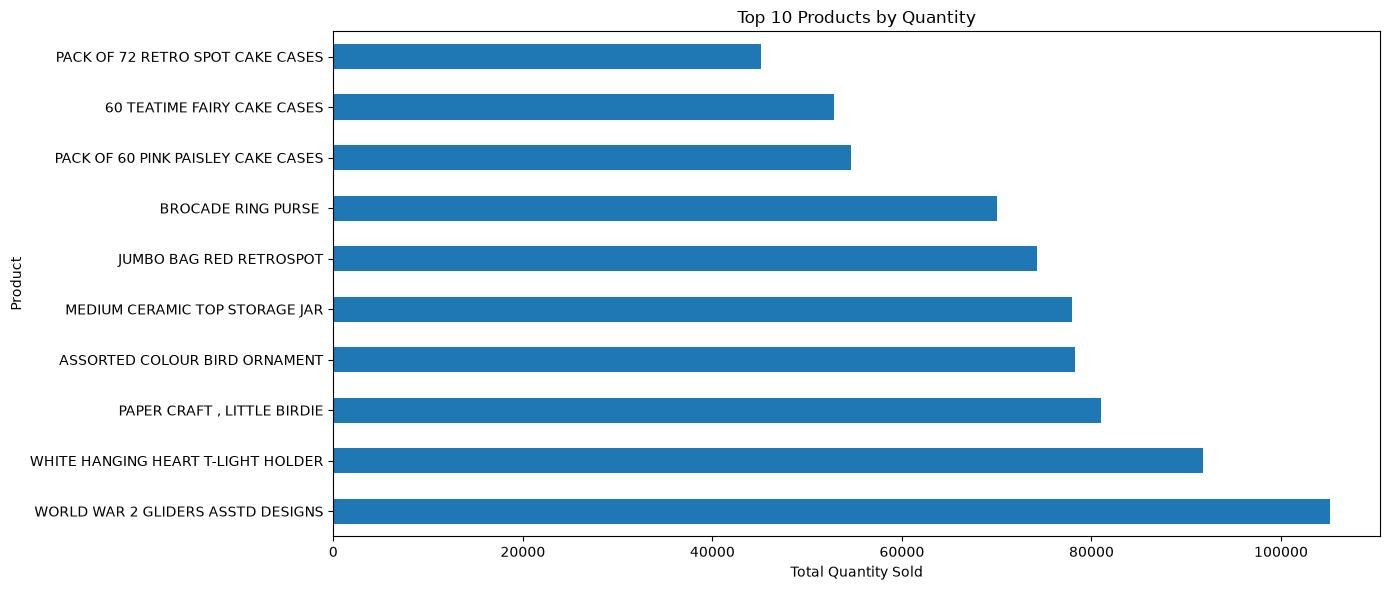

In [41]:
plt.figure(figsize=(14,6))

top_products_quantity.plot(kind="barh")

plt.title("Top 10 Products by Quantity")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [42]:
top_products_revenue = (
    df_clean.groupby("Description")["TotalPrice"]
    .sum()
    .sort_values(ascending = False)
    .head(10)
)

print(top_products_revenue)

Description
REGENCY CAKESTAND 3 TIER              277656.25
WHITE HANGING HEART T-LIGHT HOLDER    247048.01
PAPER CRAFT , LITTLE BIRDIE           168469.60
Manual                                151777.67
JUMBO BAG RED RETROSPOT               134307.44
POSTAGE                               124648.04
ASSORTED COLOUR BIRD ORNAMENT         124351.86
PARTY BUNTING                         103283.38
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
PAPER CHAIN KIT 50'S CHRISTMAS         76598.18
Name: TotalPrice, dtype: float64


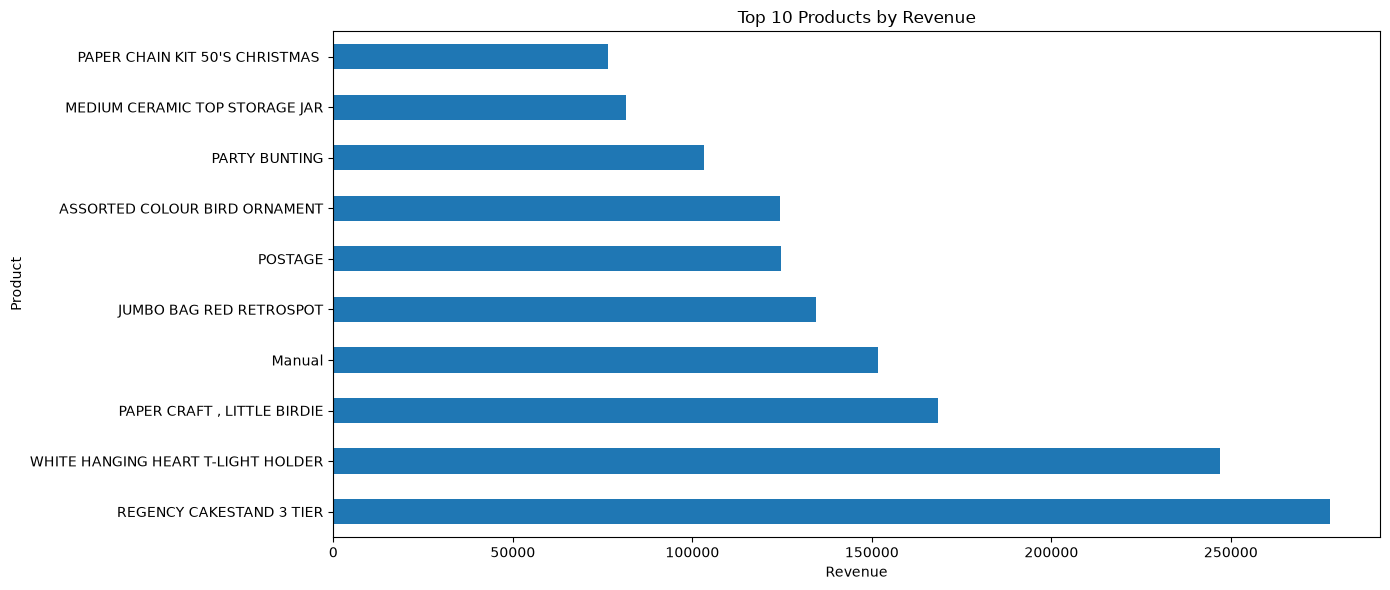

In [43]:
plt.figure(figsize=(14,6))

top_products_revenue.plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

In [45]:
df_clean["Quantity"].describe()


count    779425.000000
mean         13.489370
std         145.855814
min           1.000000
25%           2.000000
50%           6.000000
75%          12.000000
max       80995.000000
Name: Quantity, dtype: float64

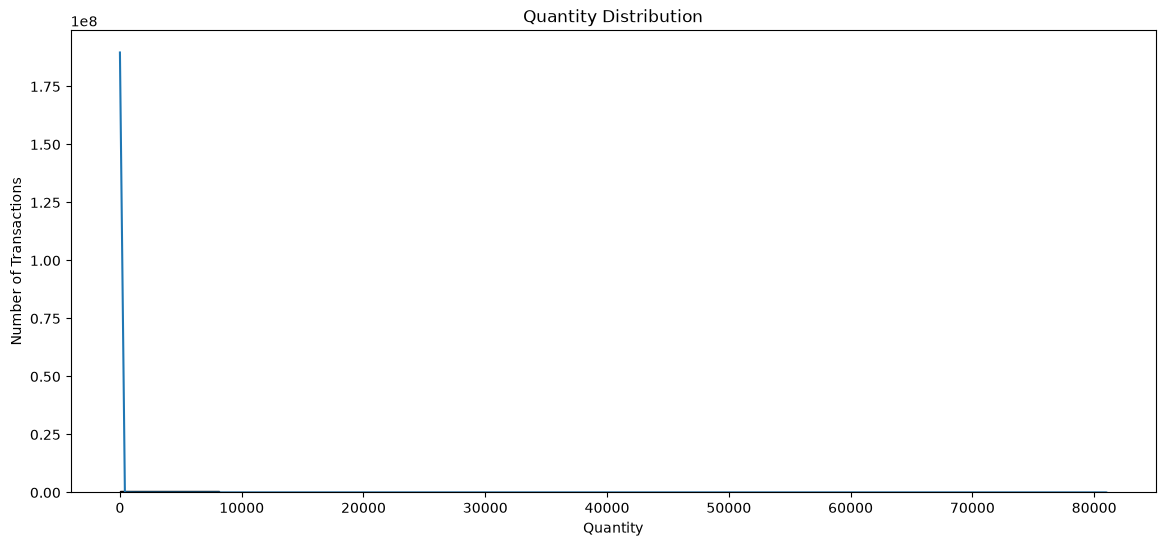

In [51]:
plt.figure(figsize=(14,6))

sns.histplot(df_clean["Quantity"],bins = 10, kde=True)

plt.title("Quantity Distribution")
plt.xlabel("Quantity")
plt.ylabel("Number of Transactions")

plt.show()

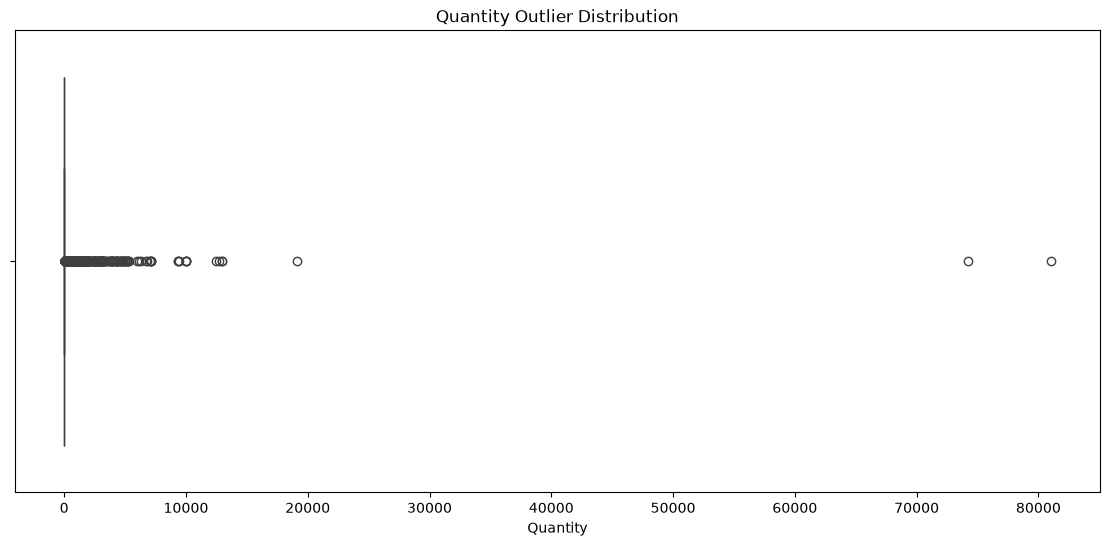

In [54]:
plt.figure(figsize=(14,6))

sns.boxplot(x=df_clean["Quantity"])

plt.title("Quantity Outlier Distribution")
plt.show()

In [55]:
df_clean["Price"].describe()

count    779425.000000
mean          3.218488
std          29.676140
min           0.001000
25%           1.250000
50%           1.950000
75%           3.750000
max       10953.500000
Name: Price, dtype: float64

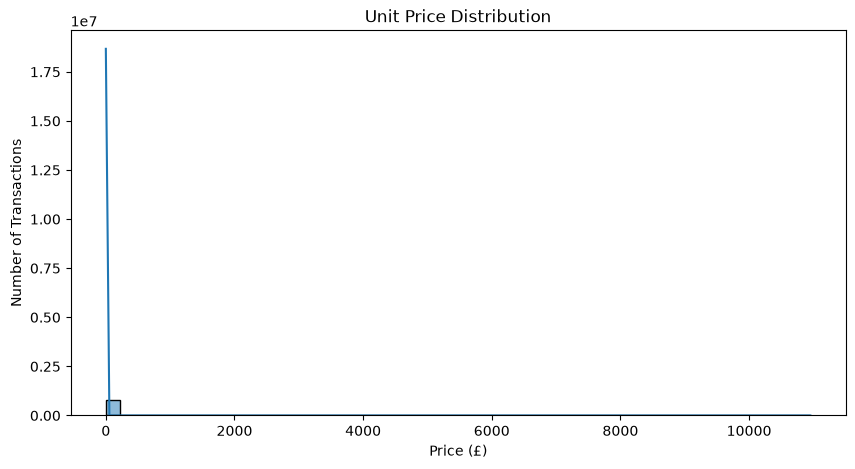

In [56]:
plt.figure(figsize=(10, 5))

sns.histplot(df_clean["Price"], bins=50, kde=True)

plt.title("Unit Price Distribution")
plt.xlabel("Price (£)")
plt.ylabel("Number of Transactions")

plt.show()

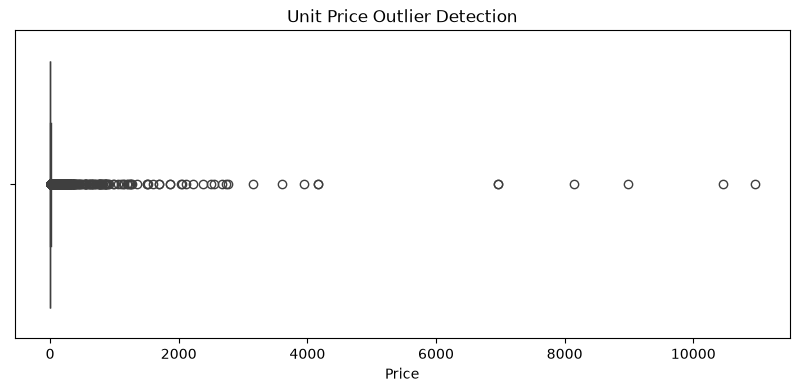

In [57]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df_clean["Price"])

plt.title("Unit Price Outlier Detection")

plt.show()

In [58]:
df_clean.nlargest(10, "Quantity")[
    ["Invoice", "StockCode", "Description",
     "Quantity", "Price", "TotalPrice", "Customer ID"]
]

,Invoice,StockCode,Description,Quantity,Price,TotalPrice,Customer ID
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,12346
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,1915.2,13902
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,1296.0,13902
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,1296.0,13902
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,1274.4,13902
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,1248.0,13902
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,2500.0,17940
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,0.25,2500.0,17940
135029,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,2500.0,17940


In [59]:
df_clean.nlargest(10, "Price")[
    ["Invoice", "StockCode", "Description",
     "Quantity", "Price", "TotalPrice", "Customer ID"]
]

,Invoice,StockCode,Description,Quantity,Price,TotalPrice,Customer ID
135013,502263,M,Manual,1,10953.50,10953.50,12918
358639,524159,M,Manual,1,10468.80,10468.80,14063
74356,496115,M,Manual,1,8985.60,8985.60,17949
698843,551697,POST,POSTAGE,1,8142.75,8142.75,16029
129903,501766,M,Manual,1,6958.17,6958.17,15760
129987,501768,M,Manual,1,6958.17,6958.17,15760
947835,573077,M,Manual,1,4161.06,4161.06,12536
947838,573080,M,Manual,1,4161.06,4161.06,12536
931867,571751,M,Manual,1,3949.32,3949.32,12744
288706,517483,M,Manual,1,3610.50,3610.50,12737


In [60]:
df_clean[df_clean["Customer ID"].isin([16446, 12346])].sort_values(
    "InvoiceDate"
)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice,YearMonth
27994,491725,TEST001,This is a test product.,10,2009-12-14 08:34:00,4.50,12346,United Kingdom,45.00,2009-12
28251,491742,TEST001,This is a test product.,5,2009-12-14 11:00:00,4.50,12346,United Kingdom,22.50,2009-12
28254,491744,TEST001,This is a test product.,5,2009-12-14 11:02:00,4.50,12346,United Kingdom,22.50,2009-12
39398,492718,TEST001,This is a test product.,5,2009-12-18 10:47:00,4.50,12346,United Kingdom,22.50,2009-12
39411,492722,TEST002,This is a test product.,1,2009-12-18 10:55:00,1.00,12346,United Kingdom,1.00,2009-12
45228,493410,TEST001,This is a test product.,5,2010-01-04 09:24:00,4.50,12346,United Kingdom,22.50,2010-01
45230,493412,TEST001,This is a test product.,5,2010-01-04 09:53:00,4.50,12346,United Kingdom,22.50,2010-01
56117,494450,TEST001,This is a test product.,5,2010-01-14 13:50:00,4.50,12346,United Kingdom,22.50,2010-01
66084,495295,TEST001,This is a test product.,5,2010-01-22 13:30:00,4.50,12346,United Kingdom,22.50,2010-01
107804,499763,15056P,EDWARDIAN PARASOL PINK,1,2010-03-02 13:08:00,5.95,12346,United Kingdom,5.95,2010-03


In [61]:
df_clean[df_clean["StockCode"].astype(str).str.match(r"^[A-Za-z]+$")][
    ["StockCode", "Description"]
].drop_duplicates().sort_values("StockCode")

,StockCode,Description
70976,ADJUST,Adjustment by john on 26/01/2010 16
71058,ADJUST,Adjustment by john on 26/01/2010 17
160443,D,Discount
842968,DOT,DOTCOM POSTAGE
11310,M,Manual
62299,PADS,PADS TO MATCH ALL CUSHIONS
89,POST,POSTAGE


In [62]:
special_codes = ["ADJUST", "D", "DOT", "M", "PADS", "POST"]

special_transactions = df_clean[
    df_clean["StockCode"].astype(str).isin(special_codes)
]

special_summary = special_transactions.groupby(
    "StockCode"
).agg(
    Transactions=("Invoice", "nunique"),
    Quantity=("Quantity", "sum"),
    Revenue=("TotalPrice", "sum"),
    Customers=("Customer ID", "nunique")
)

special_summary

,Transactions,Quantity,Revenue,Customers
StockCode,,,,
ADJUST,32,32,3538.520,25
D,5,196,397.890,5
DOT,16,16,11906.360,1
M,620,9384,151777.670,438
PADS,17,17,0.017,15
POST,1803,5235,124648.040,405


In [66]:
exclude_codes = ["ADJUST", "DOT", "M", "POST"]

df_rfm = df_clean[
    ~df_clean["StockCode"].astype(str).isin(exclude_codes)
].copy()

In [71]:
reference_date = df_rfm["InvoiceDate"].max() + pd.Timedelta(days=1)

print("Reference Date:", reference_date)

Reference Date: 2011-12-10 12:50:00


In [76]:
rfm = df_rfm.groupby("Customer ID").agg(
    Recency = ("InvoiceDate",lambda x:(reference_date-x.max()).days),
    Frequency = ("Invoice","count"),
    Monetary = ("TotalPrice","sum")
)

rfm.head()


,Recency,Frequency,Monetary
Customer ID,,,
12346,326,34,77556.46
12347,2,222,4921.53
12348,75,46,1658.40
12349,19,172,3678.69
12350,310,16,294.40


In [77]:
rfm.describe()

,Recency,Frequency,Monetary
count,5853.000000,5853.000000,5853.000000
mean,200.127969,132.731249,2918.662850
std,208.402362,342.164427,14335.739467
min,1.000000,1.000000,2.950000
25%,25.000000,21.000000,340.850000
50%,95.000000,52.000000,856.030000
75%,379.000000,138.000000,2240.900000
max,739.000000,12425.000000,580987.040000


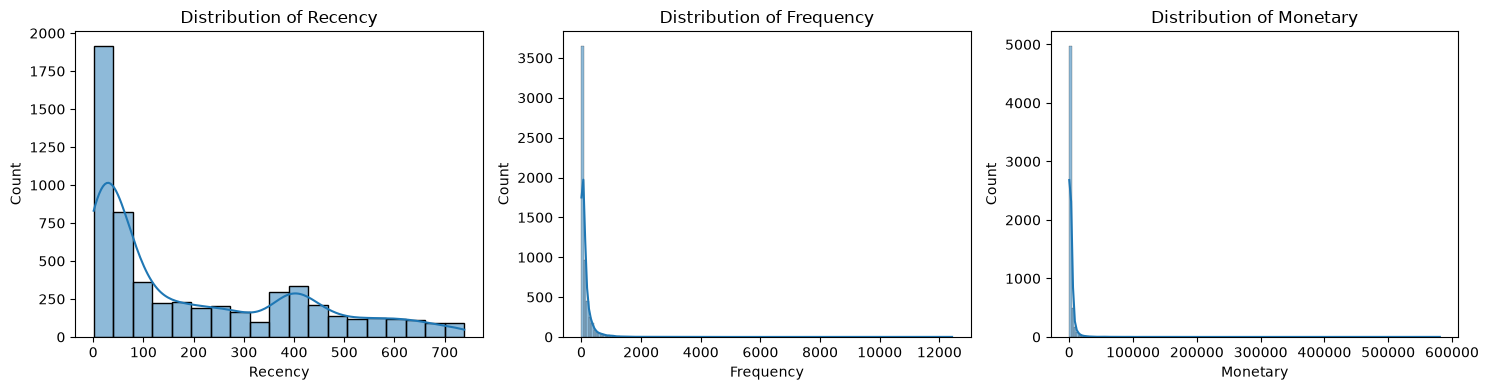

In [78]:
plt.figure(figsize=(15, 4))

for i, col in enumerate(rfm.columns, 1):
    plt.subplot(1, 3, i)
    sns.histplot(rfm[col], kde=True)
    plt.title(f"Distribution of {col}")

plt.tight_layout()
plt.show()

In [79]:
print(rfm.skew())

Recency       0.893525
Frequency    18.153939
Monetary     25.294071
dtype: float64


In [80]:
rfm_log = np.log1p(rfm)

print(rfm_log.skew())

Recency     -0.486288
Frequency   -0.004354
Monetary     0.274558
dtype: float64


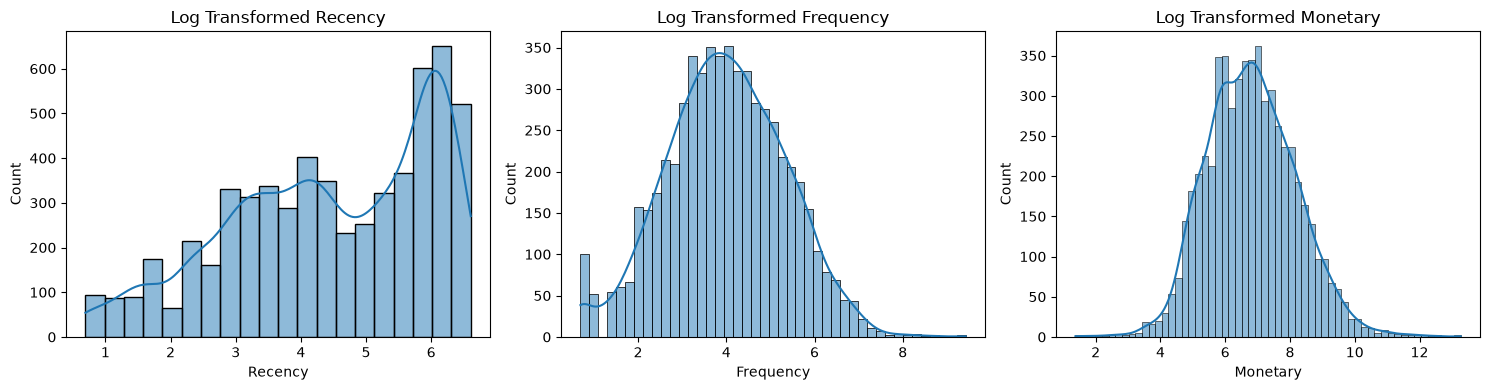

In [81]:
plt.figure(figsize=(15, 4))

for i, col in enumerate(rfm_log.columns, 1):
    plt.subplot(1, 3, i)
    sns.histplot(rfm_log[col], kde=True)
    plt.title(f"Log Transformed {col}")

plt.tight_layout()
plt.show()

In [82]:
rfm_log.describe()

,Recency,Frequency,Monetary
count,5853.000000,5853.000000,5853.000000
mean,4.448170,3.986709,6.808968
std,1.558417,1.348643,1.379908
min,0.693147,0.693147,1.373716
25%,3.258097,3.091042,5.834372
50%,4.564348,3.970292,6.753473
75%,5.940171,4.934474,7.715079
max,6.606650,9.427546,13.272485


In [86]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)
rfm_scaled = pd.DataFrame(rfm_scaled,columns=rfm_log.columns,index=rfm_log.index)
rfm_scaled.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346,0.861069,-0.319876,3.224988
12347,-2.149516,1.053343,1.226715
12348,-0.075363,-0.101267,0.438649
12349,-0.932075,0.865078,1.015818
12350,0.828875,-0.855374,-0.812180


In [87]:
print(rfm_scaled.mean())
print(rfm_scaled.std())

Recency     -1.978788e-16
Frequency    2.968182e-16
Monetary     1.651013e-16
dtype: float64
Recency      1.000085
Frequency    1.000085
Monetary     1.000085
dtype: float64


In [88]:
from sklearn.cluster import KMeans

inertia = []

for k in range(2,11):
    kmeans = KMeans(n_clusters=k,random_state=42,n_init=10)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

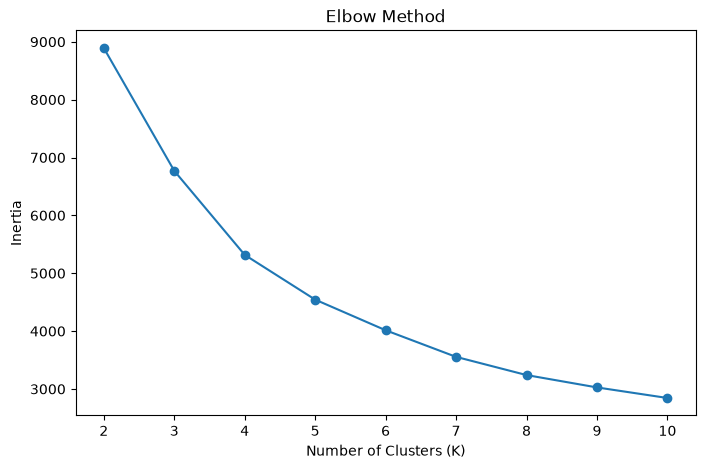

In [89]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), inertia, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [91]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2,11):
    kmeans = KMeans(n_clusters=k,n_init=10, random_state=42)
    labels = kmeans.fit_predict(rfm_scaled)
    score = silhouette_score(rfm_scaled,labels)
    silhouette_scores.append(score)
    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.4135
K = 3, Silhouette Score = 0.3152
K = 4, Silhouette Score = 0.3354
K = 5, Silhouette Score = 0.3017
K = 6, Silhouette Score = 0.2888
K = 7, Silhouette Score = 0.2877
K = 8, Silhouette Score = 0.2911
K = 9, Silhouette Score = 0.2726
K = 10, Silhouette Score = 0.2667


In [92]:
for k in [2, 4]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    rfm[f"Cluster_{k}"] = labels

    print(f"\n========== K = {k} ==========")

    print("\nCluster Sizes:")
    print(rfm[f"Cluster_{k}"].value_counts().sort_index())

    print("\nCluster Profiles:")
    print(
        rfm.groupby(f"Cluster_{k}")[["Recency", "Frequency", "Monetary"]]
        .median()
        .round(2)
    )


========== K = 2 ==========

Cluster Sizes:
Cluster_2
0    3277
1    2576
Name: count, dtype: int64

Cluster Profiles:
           Recency  Frequency  Monetary
Cluster_2                              
0            313.0       24.0    383.03
1             26.0      154.5   2502.41

========== K = 4 ==========

Cluster Sizes:
Cluster_4
0    1577
1    1287
2    1257
3    1732
Name: count, dtype: int64

Cluster Profiles:
           Recency  Frequency  Monetary
Cluster_4                              
0            242.0       71.0   1185.01
1             17.0      273.0   4505.16
2             25.0       47.0    756.39
3            397.5       14.0    231.33


In [93]:
final_kmeans = KMeans(n_clusters=4,n_init=10, random_state=42)

rfm["Cluster"] = final_kmeans.fit_predict(rfm_scaled)

print(rfm["Cluster"].value_counts().sort_index())

Cluster
0    1577
1    1287
2    1257
3    1732
Name: count, dtype: int64


In [94]:
cluster_profile = rfm.groupby("Cluster").agg(
    Customers=("Recency", "count"),
    Recency=("Recency", "median"),
    Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median")
).round(2)

print(cluster_profile)

         Customers  Recency  Frequency  Monetary
Cluster                                         
0             1577    242.0       71.0   1185.01
1             1287     17.0      273.0   4505.16
2             1257     25.0       47.0    756.39
3             1732    397.5       14.0    231.33


In [95]:
cluster_counts = rfm["Cluster"].value_counts().sort_index()

cluster_percentage = (
    cluster_counts / len(rfm) * 100
).round(2)

cluster_distribution = pd.DataFrame({
    "Customers": cluster_counts,
    "Percentage": cluster_percentage
})

print(cluster_distribution)

         Customers  Percentage
Cluster                       
0             1577       26.94
1             1287       21.99
2             1257       21.48
3             1732       29.59


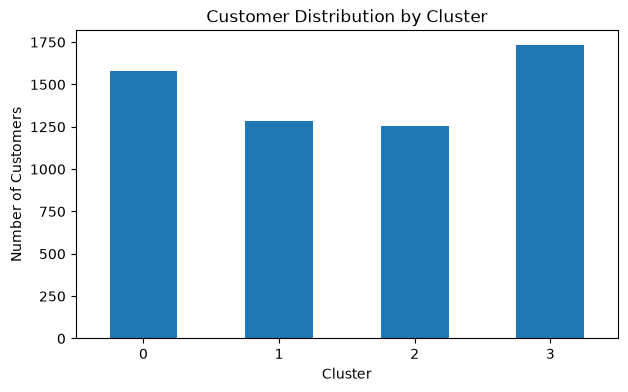

In [96]:
cluster_counts.plot(kind="bar", figsize=(7, 4))

plt.title("Customer Distribution by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

In [97]:
cluster_means_scaled = (
    rfm_scaled
    .assign(Cluster=rfm["Cluster"])
    .groupby("Cluster")
    .mean()
)

print(cluster_means_scaled.round(2))

         Recency  Frequency  Monetary
Cluster                              
0           0.62       0.24      0.24
1          -1.06       1.26      1.27
2          -0.83      -0.13     -0.17
3           0.83      -1.06     -1.04


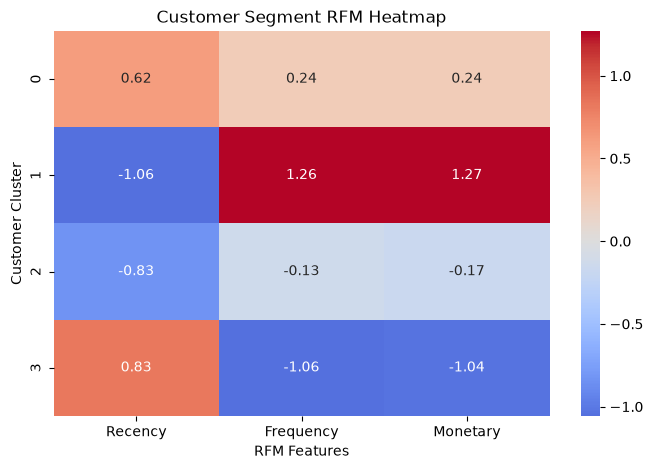

In [98]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.heatmap(
    cluster_means_scaled,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Customer Segment RFM Heatmap")
plt.xlabel("RFM Features")
plt.ylabel("Customer Cluster")
plt.show()

In [99]:
segment_names = {
    0: "At-Risk Valuable",
    1: "Champions",
    2: "Recent Low-Frequency",
    3: "Hibernating"
}

rfm["Segment"] = rfm["Cluster"].map(segment_names)

print(rfm[["Recency", "Frequency", "Monetary", "Cluster", "Segment"]].head(10))

             Recency  Frequency  Monetary  Cluster               Segment
Customer ID                                                             
12346            326         34  77556.46        0      At-Risk Valuable
12347              2        222   4921.53        1             Champions
12348             75         46   1658.40        0      At-Risk Valuable
12349             19        172   3678.69        1             Champions
12350            310         16    294.40        3           Hibernating
12351            375         21    300.93        3           Hibernating
12352             36         95   1729.54        2  Recent Low-Frequency
12353            204         24    406.76        3           Hibernating
12354            232         58   1079.40        0      At-Risk Valuable
12355            214         35    947.61        0      At-Risk Valuable


In [100]:
segment_summary = rfm.groupby("Segment").agg(
    Customers=("Recency", "count"),
    Median_Recency=("Recency", "median"),
    Median_Frequency=("Frequency", "median"),
    Median_Monetary=("Monetary", "median")
)

segment_summary["Percentage"] = (
    segment_summary["Customers"] / len(rfm) * 100
).round(2)

segment_summary = segment_summary.sort_values(
    "Median_Monetary", ascending=False
)

print(segment_summary.round(2))

                      Customers  Median_Recency  Median_Frequency  \
Segment                                                             
Champions                  1287            17.0             273.0   
At-Risk Valuable           1577           242.0              71.0   
Recent Low-Frequency       1257            25.0              47.0   
Hibernating                1732           397.5              14.0   

                      Median_Monetary  Percentage  
Segment                                            
Champions                     4505.16       21.99  
At-Risk Valuable              1185.01       26.94  
Recent Low-Frequency           756.39       21.48  
Hibernating                    231.33       29.59  


In [102]:
segment_summary.to_csv("../data/customer_segment_summary.csv")
rfm.to_csv("../data/customer_segmentation_results.csv")

In [103]:
segment_revenue = rfm.groupby("Segment")["Monetary"].sum().sort_values(
    ascending=False
)

print(segment_revenue)

Segment
Champions               1.271583e+07
At-Risk Valuable        2.750195e+06
Recent Low-Frequency    1.135804e+06
Hibernating             4.811025e+05
Name: Monetary, dtype: float64


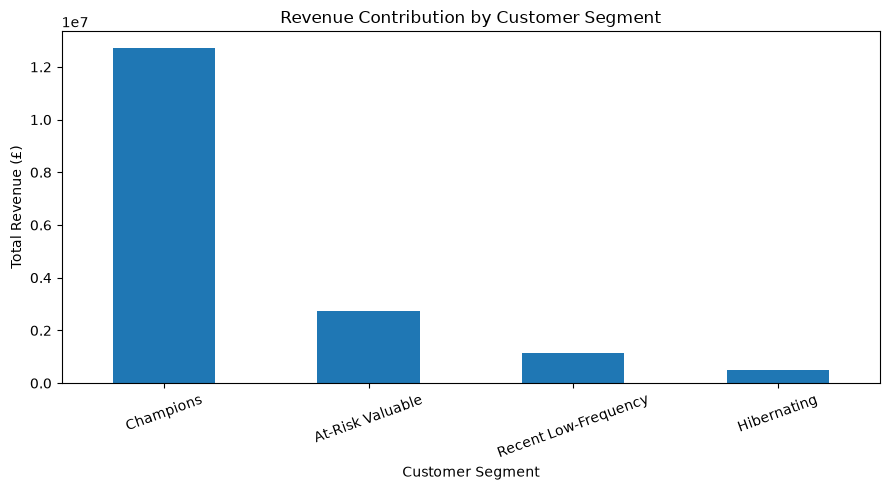

In [104]:
plt.figure(figsize=(9, 5))

segment_revenue.plot(kind="bar")

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue (£)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [105]:
revenue_percentage = (
    segment_revenue / segment_revenue.sum() * 100
).round(2)

print(revenue_percentage)

Segment
Champions               74.44
At-Risk Valuable        16.10
Recent Low-Frequency     6.65
Hibernating              2.82
Name: Monetary, dtype: float64


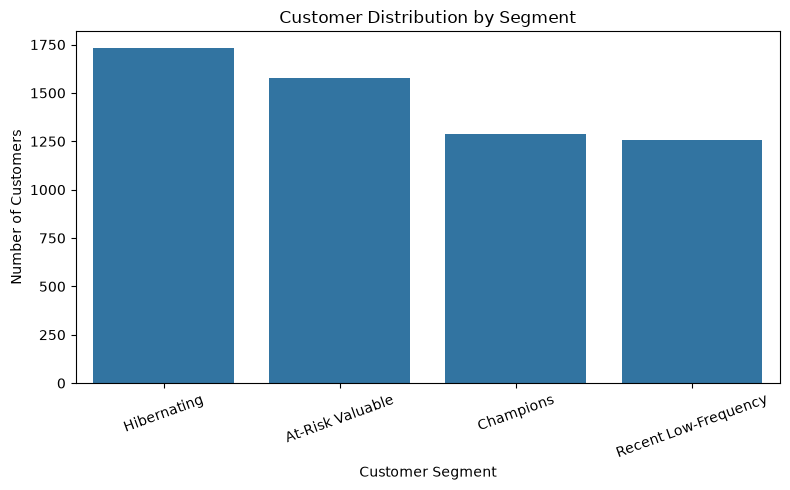

In [106]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x="Segment",
    order=rfm["Segment"].value_counts().index
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

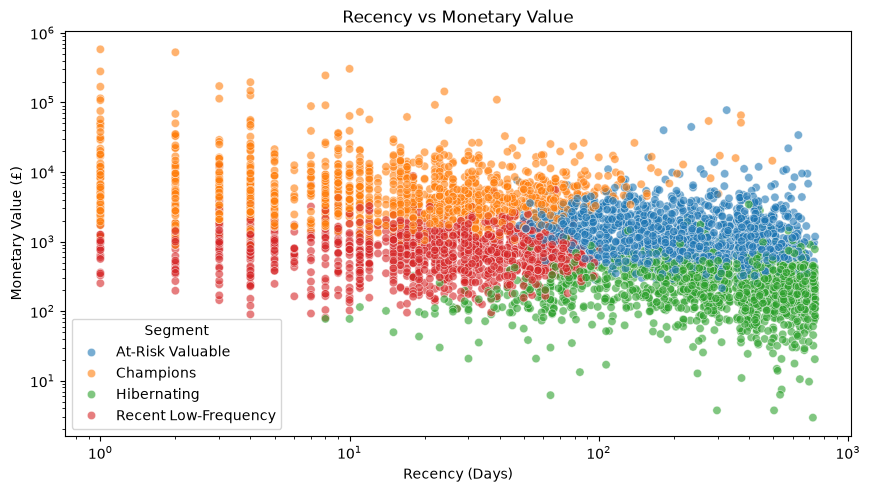

In [111]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Segment",
    alpha=0.6
)

plt.title("Recency vs Monetary Value")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary Value (£)")
plt.tight_layout()
plt.xscale("log")
plt.yscale("log")
plt.show()

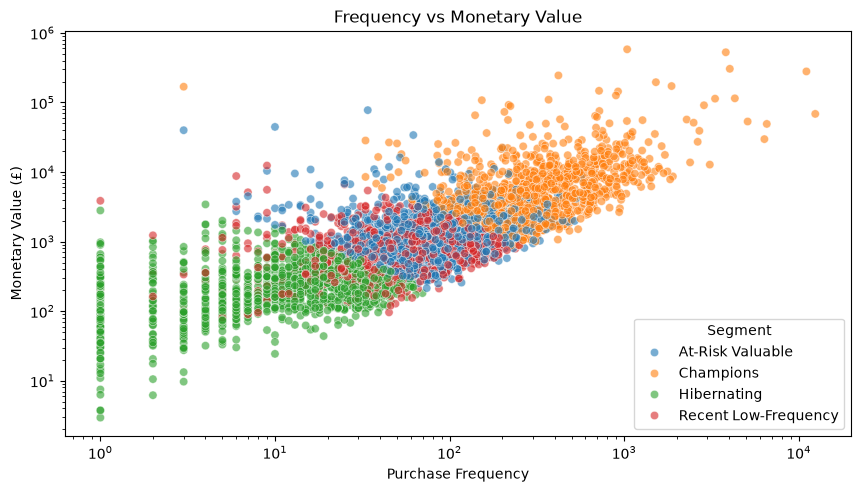

In [110]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Segment",
    alpha=0.6
)

plt.title("Frequency vs Monetary Value")
plt.xlabel("Purchase Frequency")
plt.ylabel("Monetary Value (£)")
plt.tight_layout()
plt.xscale("log")
plt.yscale("log")
plt.show()

In [112]:
from sklearn.metrics import silhouette_score

score = silhouette_score(rfm_scaled, rfm["Cluster"])

print("Final Silhouette Score:", round(score, 4))

Final Silhouette Score: 0.3354


In [ ]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(final_kmeans, "../models/kmeans_model.pkl")

joblib.dump(scaler, "../models/scaler.pkl")

print("Model and scaler saved successfully!")

Model and scaler saved successfully!
